In [1]:
# Cell 1: Set paths and processing parameters.
from pathlib import Path
import sys

# Run from training/ or its parent project directory.
TRAINING_DIR = Path.cwd().resolve()
if not (TRAINING_DIR / "superpixel_RF_GMM_training_refactored.ipynb").is_file():
    TRAINING_DIR = TRAINING_DIR / "training"
if not (TRAINING_DIR / "superpixel_RF_GMM_training_refactored.ipynb").is_file():
    raise FileNotFoundError("Start Jupyter from training/ or its parent directory.")
PROJECT_ROOT = TRAINING_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))  # Reuse matching implementation functions.
sys.path.insert(0, str(TRAINING_DIR))
RUN_DIR = TRAINING_DIR / "output" / "step1_only_001"  # Use a new name for a full-data run.
COLOR_REFERENCE_PATH = PROJECT_ROOT / "implement" / "data" / "models" / "rf_step1.pkl"
CONFIG = {
    "data_dir": "data/mag500/training",
    "max_images": None,  # All images; choose a new run for different inputs.
    "crop": {"top": 60, "bottom": 100, "left": 60, "right": 100},
    "n_segments": 300, "compactness": 10.0,
}
DATA_DIR = PROJECT_ROOT / CONFIG["data_dir"]
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Training image directory not found: {DATA_DIR}")
print(f"Project: {PROJECT_ROOT}\nTraining images: {DATA_DIR}\nRun: {RUN_DIR}")
print(f"Available JPG images: {sum(1 for p in DATA_DIR.glob('*.jpg') if p.is_file())}")

Project: /home/kmanabe2403/dune
Training images: /home/kmanabe2403/dune/data/mag500/training
Run: /home/kmanabe2403/dune/training/output/step1_only_001
Available JPG images: 166


In [2]:
# Cell 2: Save naturally sorted training image paths and settings.
# Rerunning overwrites metadata. Use a new run name when changing inputs or settings.
from training_pipeline import prepare_training_run

prepare_training_run(PROJECT_ROOT, RUN_DIR, CONFIG)

Selected images: 166 | Metadata: /home/kmanabe2403/dune/training/output/step1_only_001/metadata


In [3]:
# Cell 3: Crop images, compute SLIC segments, and save per-image Lab means.
# Process only the images selected in Cell 2 (all images by default).
from crystal_preprocessing import run_preprocessing

run_preprocessing(PROJECT_ROOT, RUN_DIR)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [4]:
# Cell 4: Save pixel-Lab corrections using the fixed reference from the existing RF model.
# Reuse the implementation function; do not recalculate the reference from these images.
from crystal_preprocessing import run_color_correction

run_color_correction(RUN_DIR, COLOR_REFERENCE_PATH)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [5]:
# Cell 5: Calculate and save the same 18 features used by implementation.
# Use archived-training rgb2gray and pixel Lab correction before averaging.
from crystal_features import run_feature_extraction

run_feature_extraction(RUN_DIR)

Prepared inputs are stored locally in this run; no previous output folder is required.


## Manual input: GMM counts

☐ Run the next cell to create `review/gmm_settings.csv`.  
☐ Enter `n_components` for every image and rerun the cell.  
・New runs start blank; fitting stops until counts are filled. Existing entries are preserved.

In [6]:
# Cell 6: Prepare run-local GMM counts for manual entry, then fit.
# First run: fill review/gmm_settings.csv and rerun this cell.
from training_pipeline import prepare_gmm_settings, run_training_gmm

GMM_SETTINGS_PATH, GMM_STAGE2_SETTINGS_PATH = prepare_gmm_settings(RUN_DIR)
run_training_gmm(RUN_DIR, GMM_SETTINGS_PATH, pca_components=2, probability_cut=0.90)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [7]:
# Cell 7: Review saved stage-1 GMM clusters and high-confidence regions.
# Change image_ids to inspect other selected images; GMM is not recalculated.
from training_review import show_training_gmm

show_training_gmm(RUN_DIR, image_ids=[0, 1, 2])

Prepared inputs are stored locally in this run; no previous output folder is required.


## Optional manual input: GMM subdivisions

☐ Inspect Cell 7 for all images.  
☐ If a parent needs another GMM split, add `name,parent_cluster,n_components` to `review/gmm_subdivision_settings.csv`.  
☐ Run Cells 8–9; header only means no subdivision.

In [8]:
# Cell 8: Optional GMM subdivision configured manually after reviewing Cell 7.
# Add name,parent_cluster,n_components to review/gmm_subdivision_settings.csv.
# A header-only CSV means no subdivision. This is annotation GMM, not child RF.
from training_pipeline import run_training_gmm_stage2

run_training_gmm_stage2(RUN_DIR, GMM_STAGE2_SETTINGS_PATH, pca_components=2, probability_cut=0.90)

Prepared inputs are stored locally in this run; no previous output folder is required.


In [9]:
# Cell 9: Inspect the optional annotation-GMM subdivisions.
import pandas as pd
from training_review import show_training_gmm_stage2

subdivision_settings = pd.read_csv(RUN_DIR / "gmm/stage2/settings.csv")
if subdivision_settings.empty:
    print("No annotation-GMM subdivisions selected; continue to Cell 10.")
else:
    REVIEW_IMAGE_IDS = [int(subdivision_settings.image_id.iloc[0])]  # Change to inspect other split images.
    show_training_gmm_stage2(RUN_DIR, image_ids=REVIEW_IMAGE_IDS)

Prepared inputs are stored locally in this run; no previous output folder is required.


## Required manual labels

☐ Run Cell 10 to create `labels/cluster_labels.csv`.  
☐ Inspect the GMM figures for every image and fill every `manual_label`.  
・Use nonnegative integers; `0` explicitly excludes a group. Do not edit cluster keys.  
・No past labels are imported. The current saved run retains its filled reproduction labels.

In [10]:
# Cell 10: Create blank human labels; preserve entries already entered in this run.
# Inspect Cells 7/9 for all images and fill labels/cluster_labels.csv manually.
# Enter an integer for every manual_label; use 0 to exclude a group.
from training_labels import prepare_training_labels

TRAINING_LABELS_PATH = prepare_training_labels(RUN_DIR)

Recorded manual labels are retained in this existing run. New runs create blank labels; fill every manual_label before Cell 11.


## Check labels before continuing

☐ Save the completed CSV, then run Cells 11–18.  
・Blank/invalid labels stop dataset building and RF training before new outputs are written.

In [11]:
# Cell 11: Assign human labels to superpixels and save the feature table.
# Keep archived parent/superpixel row order for reproducible RF bootstrap samples.
# Missing labels stop here before output; stage2_cluster=-1 means no second-stage split.
from training_dataset import build_training_dataset

TRAINING_DATASET_PATH = build_training_dataset(RUN_DIR)

Saved 41216 superpixels from 166 images: /home/kmanabe2403/dune/training/output/step1_only_001/datasets/superpixels.csv


In [12]:
# Cell 12: Review label counts and filtering before RF training.
# Label 0 remains in the source table but is excluded from training, as in the original.
from training_dataset import inspect_training_dataset

GMM_PROBABILITY_CUT = 0.70
EXCLUDED_LABELS = [0]
inspect_training_dataset(TRAINING_DATASET_PATH, GMM_PROBABILITY_CUT, EXCLUDED_LABELS)

         status  n_superpixels
       eligible          37602
 excluded_label            562
low_probability           3052
Images: 166 | Probability cut: 0.7 | Excluded labels: [0]


In [13]:
# Cell 13: Map manual labels to the original five stage-1 RF groups.
# RF labels are 0-4 in this order. Edit these groups to change the classification task.
from training_dataset import group_training_labels

RF_GROUPS = {
    "1": [11, 12, 13, 14], "2": [21, 22, 23], "3": [31, 32, 33],
    "4": [41, 42, 43, 44], "5": [51],
}
RF_TRAINING_PATH = group_training_labels(TRAINING_DATASET_PATH, RF_GROUPS, GMM_PROBABILITY_CUT, EXCLUDED_LABELS)

RF 0 (1): 4539 superpixels
RF 1 (2): 5642 superpixels
RF 2 (3): 7018 superpixels
RF 3 (4): 20313 superpixels
RF 4 (5): 24 superpixels
Unmapped eligible rows: 66 | Saved: /home/kmanabe2403/dune/training/output/step1_only_001/datasets/stage1_training.csv


In [14]:
# Cell 14: Evaluate RF on separate image groups, then fit the exported model on all eligible data.
# Identical source files stay in the same partition. Missing labels stop training safely.
from training_rf import train_stage1_rf

train_stage1_rf(PROJECT_ROOT, RUN_DIR, RF_TRAINING_PATH, test_size=0.25, n_estimators=300, random_state=0)

Held-out accuracy: 0.7663 | Macro F1: 0.6512
Model refitted on 37536 eligible superpixels. Saved: /home/kmanabe2403/dune/training/output/step1_only_001/models/stage1


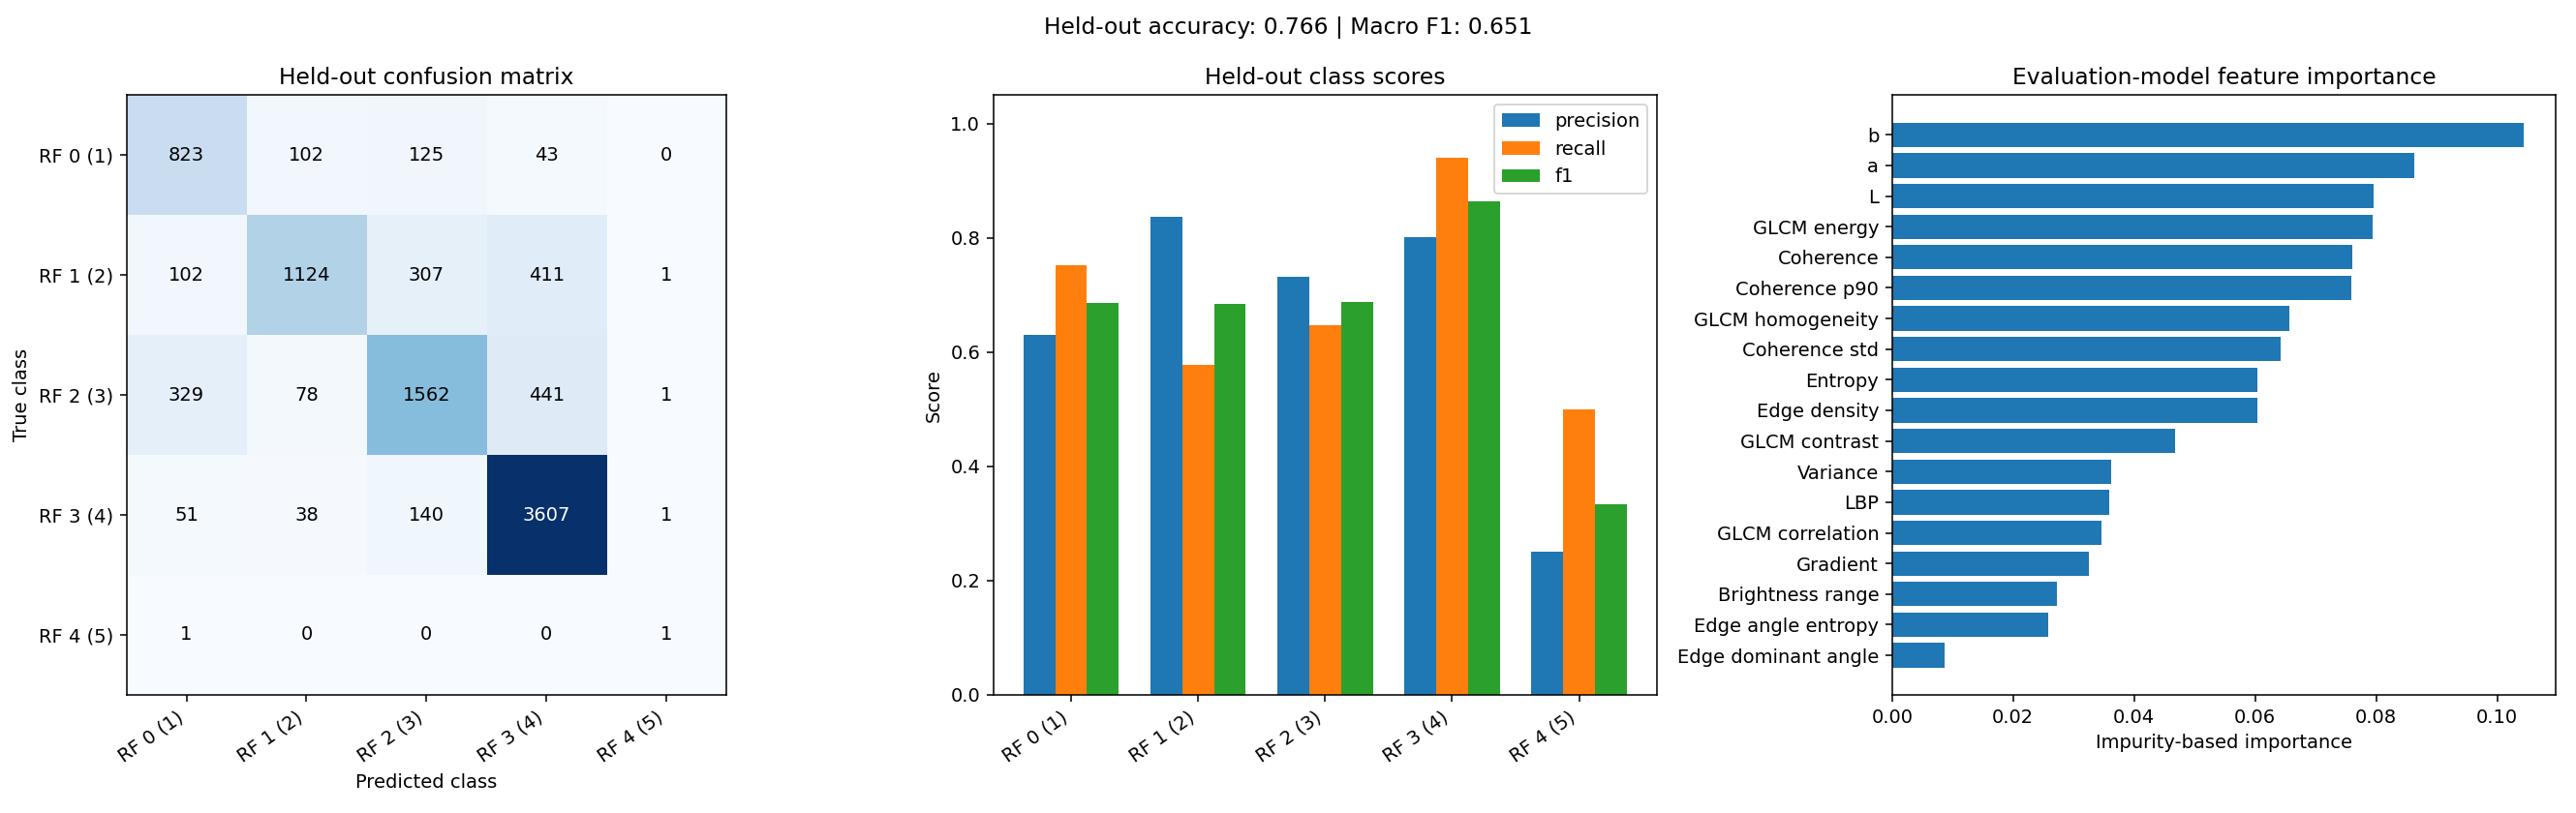

 rf_label     name  precision   recall       f1  support
        0 RF 0 (1)   0.630168 0.752973 0.686119     1093
        1 RF 1 (2)   0.837556 0.577892 0.683906     1945
        2 RF 2 (3)   0.731959 0.647864 0.687349     2411
        3 RF 3 (4)   0.801199 0.940057 0.865092     3837
        4 RF 4 (5)   0.250000 0.500000 0.333333        2
Saved: /home/kmanabe2403/dune/training/output/step1_only_001/models/stage1/evaluation


In [15]:
# Cell 15: Review held-out confusion, class scores, and feature importance.
# Saved evaluation outputs are used; no RF training is repeated.
from training_evaluation import show_rf_evaluation

show_rf_evaluation(RUN_DIR, top_features=18)

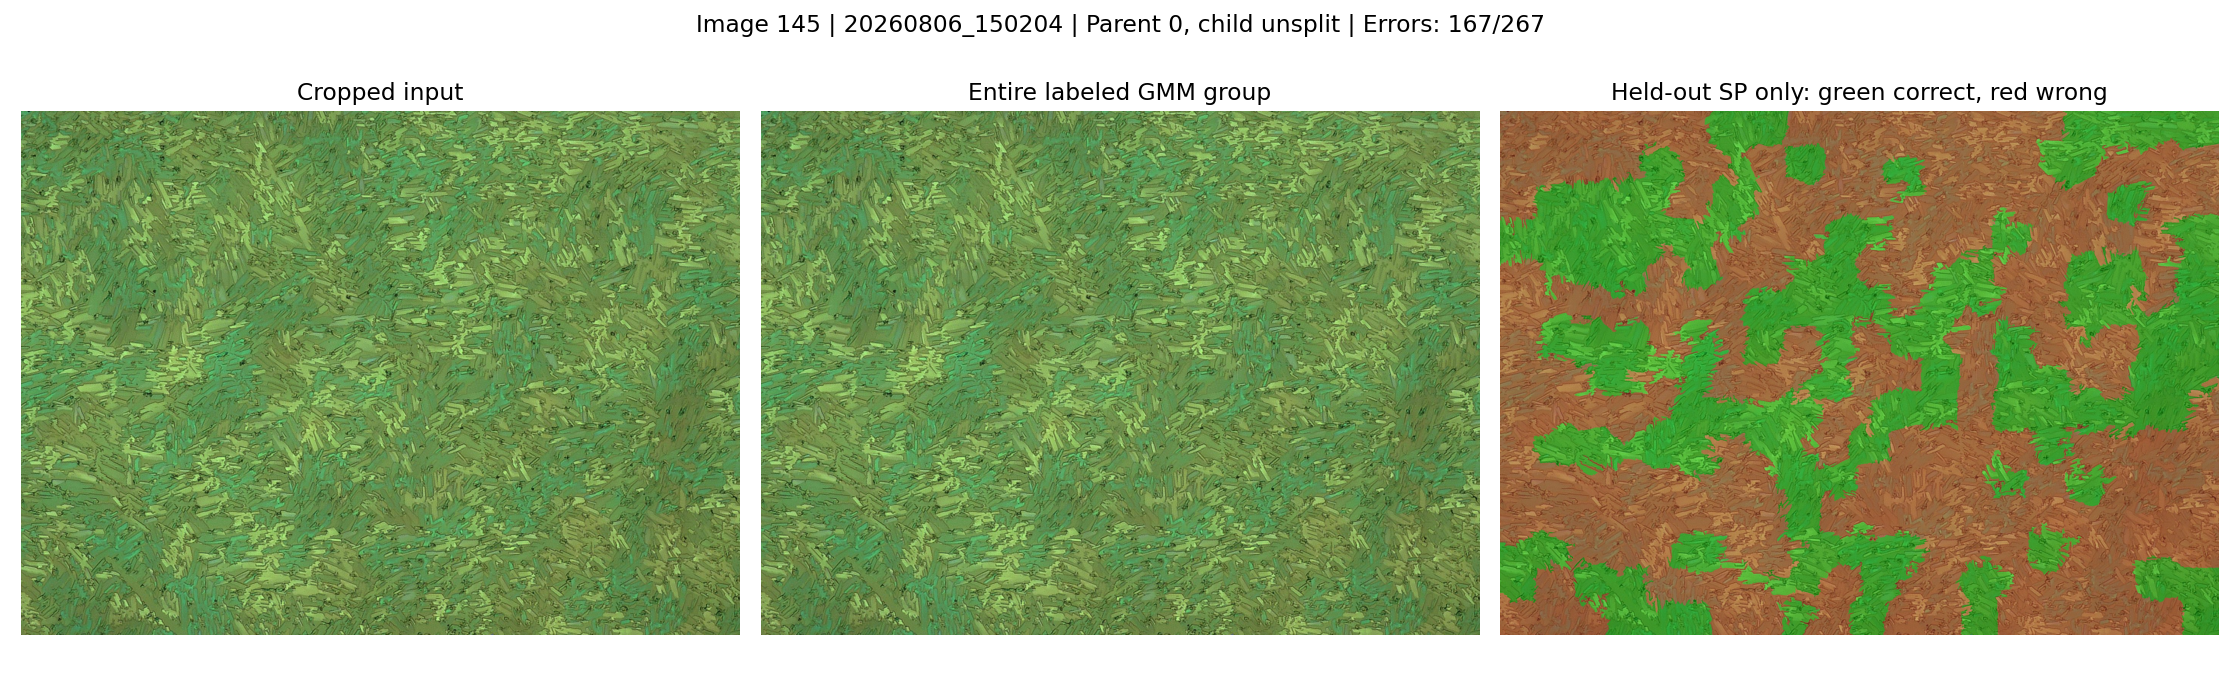

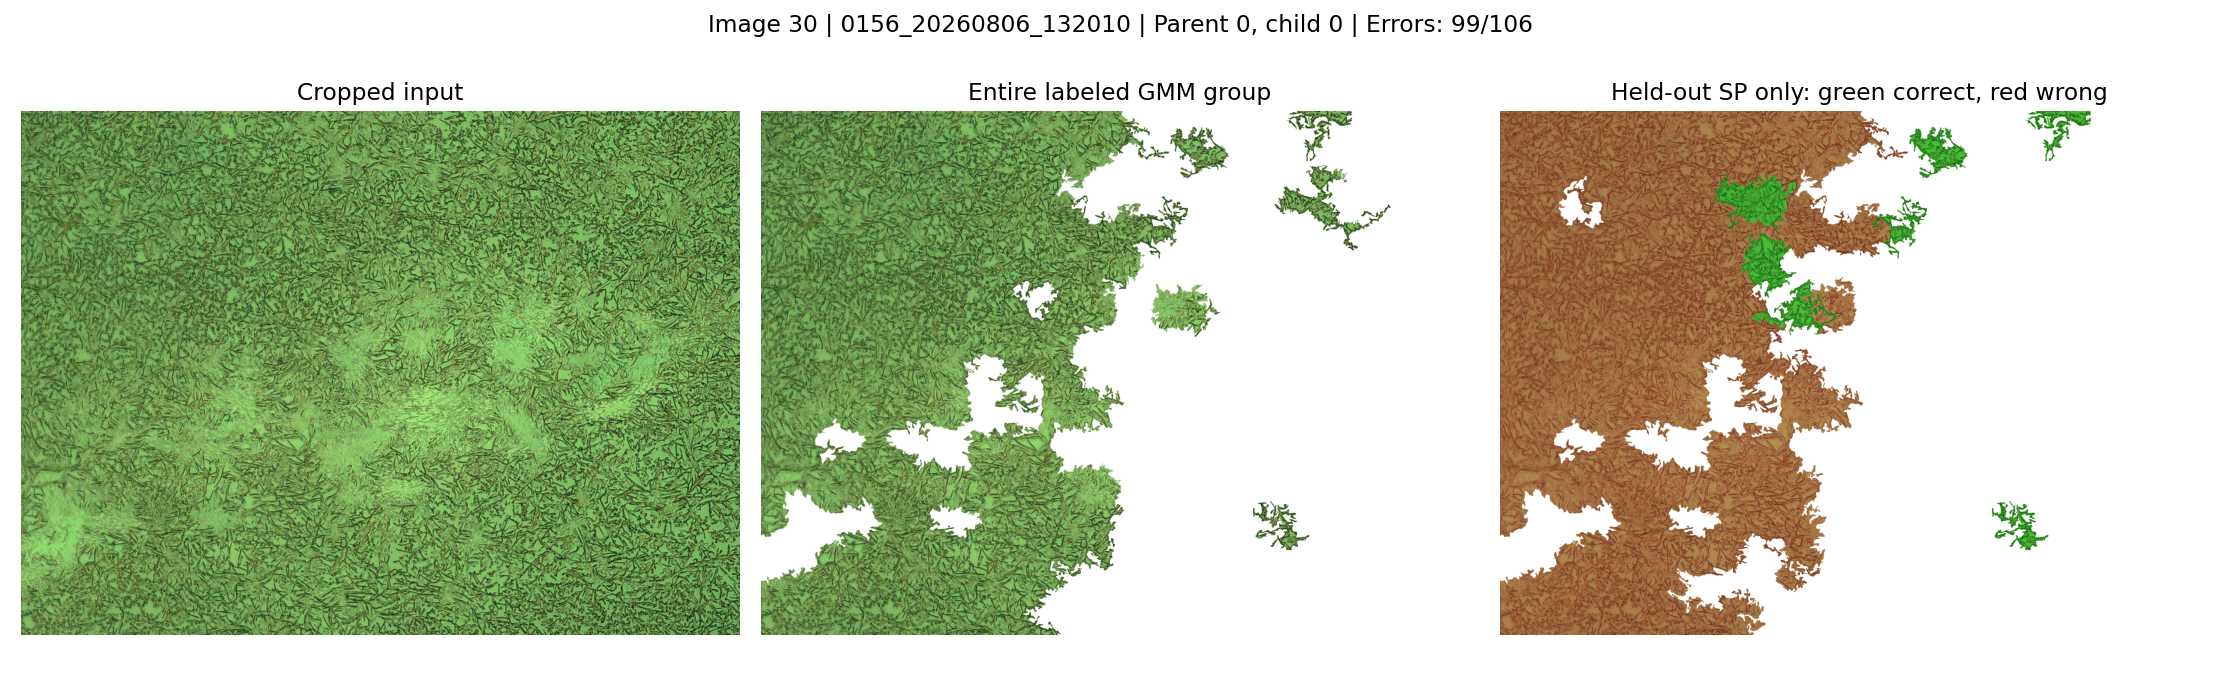

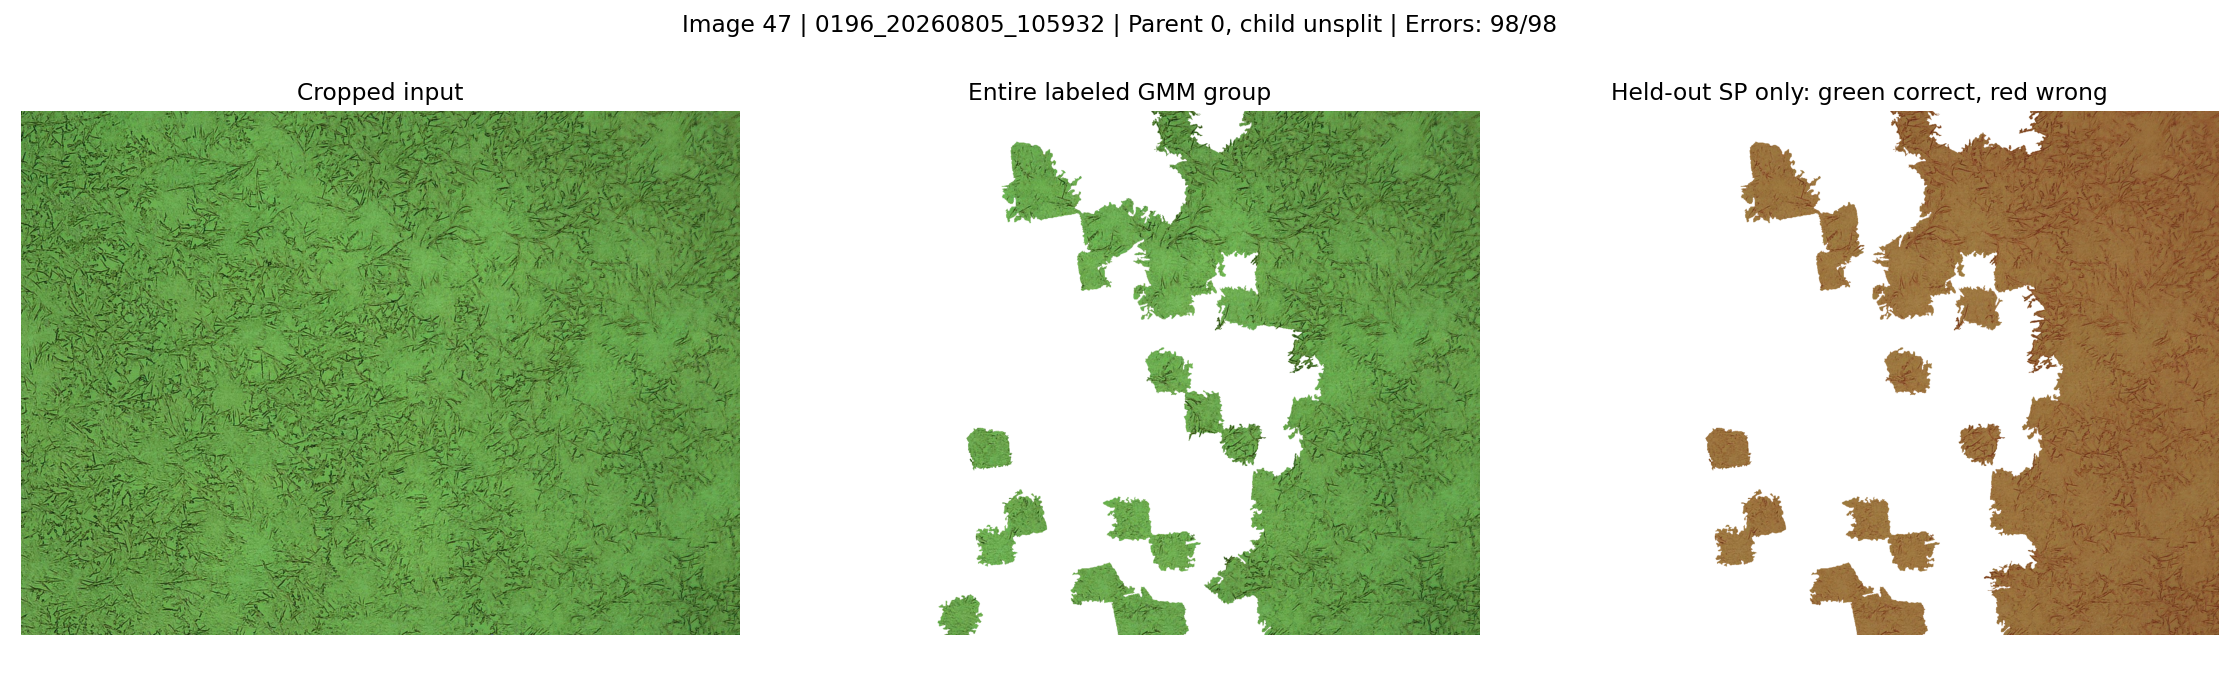

Saved 3 error-group figures: /home/kmanabe2403/dune/training/output/step1_only_001/models/stage1/evaluation/misclassifications


In [16]:
# Cell 16: Inspect the GMM groups with the most held-out classification errors.
# The colored panel shows evaluated SPs only: green is correct and red is incorrect.
from training_evaluation import show_rf_errors

show_rf_errors(RUN_DIR, max_groups=3)

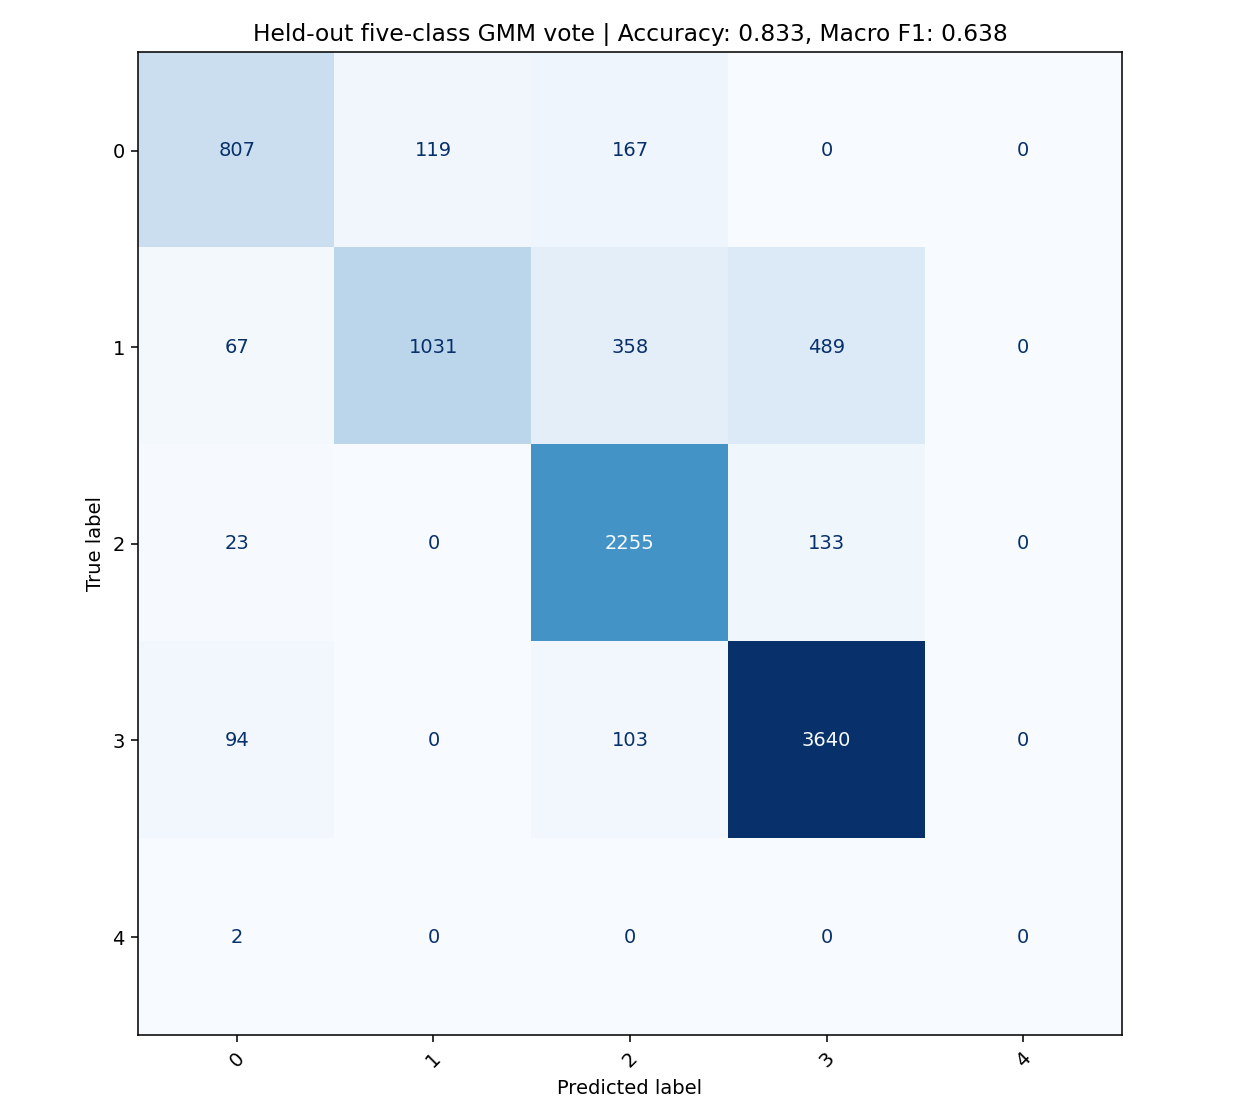

       method  accuracy  macro_f1
      RF only  0.766258   0.65116
RF + GMM vote  0.832580   0.63815
Held-out five-class GMM vote accuracy: 0.8326 | Saved: /home/kmanabe2403/dune/training/output/step1_only_001/models/stage1/gmm_evaluation


In [17]:
# Cell 17: Evaluate five-class GMM majority voting on the same held-out images.
# Only the training-partition RF is used; no child RF models are loaded.
from training_bundle import evaluate_stage1_gmm

evaluate_stage1_gmm(PROJECT_ROOT, RUN_DIR)

In [18]:
# Cell 18: Export only the five-class RF and its fixed color reference.
from training_bundle import export_implement_bundle

export_implement_bundle(RUN_DIR)

Exported step1 RF and color reference: /home/kmanabe2403/dune/training/output/step1_only_001/export/implement_bundle
